In [ ]:
# Общие импорты и локальные данные JERICHON
import os, sys
from pathlib import Path

_HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd())).expanduser().resolve()
_CANDIDATES = [_HERE, *_HERE.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in dict.fromkeys(_CANDIDATES)
                     if (p / "src" / "data" / "load_data.py").is_file()
                     and (p / "research").is_dir()), None)
if PROJECT_ROOT is None and os.environ.get("JERICHON_PROJECT_ROOT"):
    PROJECT_ROOT = Path(os.environ["JERICHON_PROJECT_ROOT"]).expanduser().resolve()
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "data" / "load_data.py").is_file():
    raise FileNotFoundError("Не найден корень JERICHON с src/data/load_data.py")
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "data")]
from src.data.load_data import *
ROOT = PROJECT_ROOT


# JERICHON AFML 06 — оптимизация сборки датасета + PCA/DBSCAN и сравнение моделей

**Цель:** улучшать предсказание направления `-1/+1` по macro-F1, оптимизируя в первую очередь параметры формирования данных/разметки, а не гиперпараметры Random Forest. Дополнительно проверяем, помогает ли добавление кластерного режима после корректной нормализации и PCA.

**Что перебирает Optuna:** `dollar_threshold`, `cusum_threshold`, `pt_mult`, `sl_mult`, `vertical_horizon`, `target_window`, `scaler`, `pca_components`, `dbscan_eps`, `dbscan_min_samples`.

**Вычислительная дисциплина:** максимум 25 trials на временной fold; кэширование дорогих этапов по ключам конфигурации; промежуточные CSV/JSON; один тикер за запуск. API не вызывается — используются только локальные AlgoPack-файлы.

**Важно:** здесь macro-F1 и F1 класса `+1` — критерии предсказания, а не доказательство положительной доходности. Финальный тест не участвует в подборе. Идея 4 (отдельное исследование режимов по волатильности/тренду/ликвидности) намеренно не включена.

## 0. Настройки запуска

Сначала запусти на одном тикере. Диапазоны можно сузить после первого запуска. Кэш хранится на диске, поэтому повторные trials с уже рассчитанной сборкой смогут повторно использовать признаки/разметку. Размеры кеша зависят от объёма истории.

In [2]:
from pathlib import Path
import os, sys, json, math, hashlib, warnings, inspect, gc, re
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

TICKER = "YDEX"
MSK = "Europe/Moscow"
SEED = 63
EXPECTED_FEATURES = 474
N_TRIALS_PER_FOLD = 50
RF_N_ESTIMATORS = 250
RF_MAX_DEPTH = 10
RF_MIN_SAMPLES_LEAF = 8
RF_MAX_FEATURES = "sqrt"

# Диапазоны оптимизации сборки датасета
DOLLAR_THRESHOLDS = list(np.linspace(5_000_000, 15_000_000, 11)) #[5_000_000, 7_500_000, 10_000_000, 12_500_000, 15_000_000]
CUSUM_RANGE = (0.0003, 0.0030)  # log-uniform
PT_SL_RANGE = (0.6, 2.0)        # step 0.2
VERTICAL_HORIZONS = [20, 30, 40, 50, 60, 80, 100]
TARGET_WINDOWS = [30, 40, 50, 55, 60, 75, 100]

# Параметры PCA/DBSCAN: ограничиваем размер пространства для практичной работы на RAM.
PCA_COMPONENT_CHOICES = [5, 8, 10, 12, 15]
DBSCAN_EPS_RANGE = (0.5, 4.0)
DBSCAN_MIN_SAMPLES_CHOICES = [5, 10, 15, 20, 30]
SCALERS = ["standard", "robust"]

# Результаты и cache в папке репозитория
PROJECT_ROOT = None  # Можно вручную задать Path(r"C:\...\JERICHON")
CACHE_DIR_NAME = "afml06_cache"
OUT_DIR_NAME = "research/afml/afml_06_data_cluster_model_zoo/results"

optuna.logging.set_verbosity(optuna.logging.WARNING)
print("Ticker:", TICKER, "| trials/fold:", N_TRIALS_PER_FOLD)

Ticker: YDEX | trials/fold: 50


## 1. Найти корень проекта и загрузить локальную историю

In [3]:

ROOT = PROJECT_ROOT
DATA_ROOT = ROOT / "data" if (ROOT / "data").exists() else ROOT
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.data.builders import jerichon_feature_pipeline as jfp
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

CACHE_DIR = DATA_ROOT / CACHE_DIR_NAME
OUT_DIR = ROOT / OUT_DIR_NAME
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("History:", HISTORY_ROOT)
print("Pipeline:", inspect.getfile(jfp))

data, SAVED_DATES = load_local_history(TICKER, HISTORY_ROOT)

Project root: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON
History: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Даты: 38 | 2026-08-28 → 2026-10-29


,источник,строк
0,candles,34605
1,trades,1981641
2,orderbook,720
3,tradestats,6952
4,obstats,6779
5,orderstats,7002


## 2. Построение и кэширование признаков

Ключ кэша включает тикер, денежный порог и версию пайплайна. Сохраняем баровые OHLC отдельно от 474 признаков. Если `dollar_threshold` меняется, Dollar Bars и признаки пересчитываются; если меняются только CUSUM/Triple Barrier/DBSCAN, дорогой feature-build повторно не запускается.

Если код пайплайна изменится, увеличь `CACHE_VERSION`, чтобы не использовать старый кэш.

In [4]:
CACHE_VERSION = "v1"
REQUIRED_HELPERS=("build_dollar_bars_from_trades","_base","_build_sc_features","_choose_availability","_attach_source")
missing=[x for x in REQUIRED_HELPERS if not hasattr(jfp,x)]
if missing: raise RuntimeError(f"В pipeline отсутствуют helper-функции: {missing}")


def cache_key(payload):
    raw=json.dumps(payload,sort_keys=True,default=str).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()[:20]


def normalize_time_col(frame, candidates=("bar_ts","close_time","ts")):
    frame=frame.copy()
    if "bar_ts" not in frame.columns:
        found=next((x for x in candidates if x in frame.columns),None)
        if found is None and isinstance(frame.index,pd.DatetimeIndex): frame=frame.reset_index().rename(columns={frame.index.name or "index":"bar_ts"})
        elif found is not None: frame=frame.rename(columns={found:"bar_ts"})
    if "bar_ts" not in frame.columns: raise RuntimeError(f"Нет временной колонки; columns={list(frame.columns)[:20]}")
    frame["bar_ts"]=pd.to_datetime(frame["bar_ts"],errors="coerce",utc=True)
    return frame.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts",keep="last").reset_index(drop=True)


def resolve_feature_frame(source, frames):
    if source in frames: return frames[source]
    matches=[k for k in frames if source.lower() in str(k).lower()]
    if len(matches)==1: return frames[matches[0]]
    raise RuntimeError(f"Не удалось сопоставить {source} с feature frame: {list(frames)}")


def build_features_for_dollar_threshold(dollar_threshold):
    key=cache_key({"version":CACHE_VERSION,"ticker":TICKER,"dollar_threshold":int(dollar_threshold)})
    feature_path=CACHE_DIR/f"{TICKER}_{key}_features.parquet"
    bars_path=CACHE_DIR/f"{TICKER}_{key}_bars.parquet"
    if feature_path.exists() and bars_path.exists():
        try:
            ft=pd.read_parquet(feature_path); b=pd.read_parquet(bars_path)
            ft=normalize_time_col(ft); b=normalize_time_col(b)
            print(f"CACHE HIT threshold={dollar_threshold:,}: bars={len(b):,}, features={len(ft):,}")
            return ft,b
        except Exception as e:
            print("Кэш повреждён/несовместим, пересобираю:",repr(e))

    b= jfp.build_dollar_bars_from_trades(data["trades"],threshold=int(dollar_threshold))
    if b is None or b.empty: raise RuntimeError(f"Пустые Dollar Bars при threshold={dollar_threshold}")
    b=normalize_time_col(b)
    base=jfp._base(b.copy())
    if isinstance(base,tuple): base=base[0]
    if not isinstance(base,pd.DataFrame): raise TypeError("jfp._base должен вернуть DataFrame")
    base=normalize_time_col(base)

    bsc=b.copy()
    if "ts" not in bsc.columns: bsc["ts"]=bsc["bar_ts"]
    if "CLOSE" not in bsc.columns:
        if "close" in bsc.columns: bsc["CLOSE"]=bsc["close"]
        else: raise RuntimeError("В Dollar Bars нет close/CLOSE")
    bsc["ts"]=pd.to_datetime(bsc["ts"],errors="coerce",utc=True)
    sc_result=jfp._build_sc_features(data,bsc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True))
    feature_frames=sc_result[0] if isinstance(sc_result,tuple) else sc_result
    if not isinstance(feature_frames,dict): raise TypeError("_build_sc_features должен вернуть dict")
    # Сохраняем диагностику availability; фактическое присоединение делаем по контракту pipeline.
    for source in ("tradestats","obstats","orderstats"):
        jfp._choose_availability(data[source].copy(),source)
    causal=b.copy()
    for source in ("tradestats","obstats","orderstats"):
        attached=jfp._attach_source(causal,resolve_feature_frame(source,feature_frames),data[source],source)
        if isinstance(attached,pd.DataFrame): causal=attached

    base_cols=[x for x in base.columns if x!="bar_ts" and pd.api.types.is_numeric_dtype(base[x])]
    if len(base_cols)!=73: raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}")
    bj=base[["bar_ts"]+base_cols].copy().rename(columns={x:f"base__{x}" for x in base_cols})
    causal=normalize_time_col(causal)
    causal=causal.merge(bj,on="bar_ts",how="left",validate="one_to_one")
    prov=[x for x in causal.columns if x.endswith("__event_ts") or x.endswith("__available_at")]
    prefixes=("tradestats__","obstats__","orderstats__")
    sc_cols=[x for x in causal.columns if x.startswith(prefixes) and x not in prov and pd.api.types.is_numeric_dtype(causal[x])]
    feat_cols=[x for x in causal.columns if x.startswith("base__")]+sc_cols
    if len(feat_cols)!=EXPECTED_FEATURES:
        raise RuntimeError(f"Инвентаризация признаков: {len(feat_cols)} вместо {EXPECTED_FEATURES}. Не запускаю оптимизацию на неполном наборе.")
    ft=causal[["bar_ts"]+feat_cols+prov].copy()
    ft=normalize_time_col(ft)
    b=normalize_time_col(b)
    # Atomic-ish writes: temporary file then replace.
    ft_tmp=feature_path.with_suffix(".tmp.parquet"); b_tmp=bars_path.with_suffix(".tmp.parquet")
    ft.to_parquet(ft_tmp,index=False); b.to_parquet(b_tmp,index=False)
    ft_tmp.replace(feature_path); b_tmp.replace(bars_path)
    print(f"CACHE BUILD threshold={dollar_threshold:,}: bars={len(b):,}, features={len(ft):,}")
    return ft,b

## 3. Построение разметки, purge и фиксированные временные folds

Классы `TIME/0` исключаются, как в предыдущем AFML-эксперименте. При обучении удаляются события, чей `t1` пересекает начало валидационного интервала. Важно: `t1` — время завершения события/метки; purge нужен, чтобы будущий исход обучающей метки не пересекал валидационный период.

In [5]:
def build_labeled_dataset(feature_frame,bars_frame,cusum_threshold,pt_mult,sl_mult,vertical_horizon,target_window):
    b=normalize_time_col(bars_frame).set_index("bar_ts",drop=False)
    close=pd.to_numeric(b["close"] if "close" in b else b["CLOSE"],errors="coerce").astype(float)
    events=pd.DatetimeIndex(cusum_filter(close,threshold=float(cusum_threshold)))
    events=events[events.isin(b.index)].drop_duplicates().sort_values()
    if len(events)<100: return None
    ren={}
    for lo,up in [("open","OPEN"),("high","HIGH"),("low","LOW"),("close","CLOSE")]:
        if lo not in b.columns and up in b.columns: ren[up]=lo
    lb=b.rename(columns=ren)
    req=["open","high","low","close"]
    if any(x not in lb.columns for x in req): raise RuntimeError(f"OHLC missing for labeling: {lb.columns.tolist()}")
    label_bars=lb[req].rename(columns={"open":"OPEN","high":"HIGH","low":"LOW","close":"CLOSE"}).copy()
    labels=triple_barrier_labeling(bars=label_bars,events=events,pt_sl=(float(pt_mult),float(sl_mult)),
        vertical_barrier=int(vertical_horizon),target_window=int(target_window),target_method="ewm")
    if labels is None or labels.empty or not {"label","t1"}.issubset(labels.columns): return None
    labels=labels.copy(); labels.index=pd.to_datetime(labels.index,errors="coerce",utc=True)
    labels=labels[~labels.index.isna()].sort_index(); labels=labels[labels["label"].isin([-1,0,1])].copy()
    labels["label"]=labels["label"].astype(int); labels["t1"]=pd.to_datetime(labels["t1"],errors="coerce",utc=True)
    ft=normalize_time_col(feature_frame).set_index("bar_ts")
    common=ft.index.intersection(labels.index); labels=labels.loc[common].sort_index()
    X=ft.reindex(labels.index).drop(columns=[x for x in ft.columns if x.endswith("__event_ts") or x.endswith("__available_at")],errors="ignore")
    mask=labels["label"].isin([-1,1]) & labels["t1"].notna()
    X=X.loc[mask]; labels=labels.loc[mask].copy(); y=labels["label"].map({-1:0,1:1}).astype(int)
    X=X.replace([np.inf,-np.inf],np.nan)
    # Remove globally empty/constant columns only; fit imputer/scalers strictly within folds.
    keep=[col for col in X.columns if X[col].notna().any() and X[col].nunique(dropna=True)>1]
    X=X[keep]
    if len(X)<200 or y.nunique()<2: return None
    return X,y,labels


def make_fixed_folds(index):
    # Валидационные блоки определяются по времени, а не по количеству событий в каждом trial.
    idx=pd.DatetimeIndex(index).sort_values().unique(); n=len(idx); folds=[]
    for name,a,b in [("WF1",0.50,0.65),("WF2",0.65,0.80),("WF3",0.80,0.95)]:
        i=max(1,int(n*a)); j=min(n,int(n*b))
        if i<100 or j-i<30: continue
        folds.append({"name":name,"train_end_ts":idx[i-1],"val_start":idx[i],"val_end":idx[j-1]})
    return folds

# Индекс календарных блоков фиксируем по baseline конфигурации, чтобы trials сравнивались на близких периодах.
BASELINE_THRESHOLD=10_000_000
baseline_ft,baseline_bars=build_features_for_dollar_threshold(BASELINE_THRESHOLD)
BASELINE_DATA=build_labeled_dataset(baseline_ft,baseline_bars,0.001,1.0,1.0,50,55)
if BASELINE_DATA is None: raise RuntimeError("Baseline labels too few/invalid; inspect data before optimization")
_,_,baseline_labels=BASELINE_DATA
FIXED_FOLDS=make_fixed_folds(baseline_labels.index)
if len(FIXED_FOLDS)<2: raise RuntimeError(f"Недостаточно временных folds: {len(FIXED_FOLDS)}")
print("Fixed folds:",[(f["name"],str(f["train_end_ts"]),str(f["val_start"]),str(f["val_end"])) for f in FIXED_FOLDS])

C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

CACHE BUILD threshold=10,000,000: bars=12,641, features=12,641
Fixed folds: [('WF1', '2026-10-02 06:48:07+00:00', '2026-10-02 07:09:54+00:00', '2026-10-09 11:45:54+00:00'), ('WF2', '2026-10-09 11:45:54+00:00', '2026-10-09 11:46:04+00:00', '2026-10-19 07:46:54+00:00'), ('WF3', '2026-10-19 07:46:54+00:00', '2026-10-19 08:00:15+00:00', '2026-10-28 15:17:51+00:00')]


## 4. Метрики, нормализация, PCA и DBSCAN

**Нормализация выполняется внутри каждого fold и только по train:** `StandardScaler` (среднее 0, стандартное отклонение 1) или `RobustScaler` (медиана и межквартильный размах). Imputer также обучается только на train.

PCA обучается на нормированных train-признаках. DBSCAN ищет кластеры в первых выбранных компонентах. У DBSCAN нет штатного `predict` для новых данных: валидационные точки назначаются ближайшему core-point только если расстояние не превышает `eps`; иначе это `-1` (неизвестный/шум). Это приближение явно диагностируется. Для каждого trial сохраняем долю шума и число кластеров.

Оптимизируем **средний macro-F1 по временным folds**. Если кластеризация вырождается (один кластер, нет кластеров или почти все точки — шум), trial штрафуется/отклоняется, чтобы оптимизатор не выбирал бессмысленные конфигурации.

In [6]:
def score_predictions(y_true,y_pred):
    return {"f1_macro":float(f1_score(y_true,y_pred,average="macro",zero_division=0)),
            "f1_up":float(f1_score(y_true,y_pred,pos_label=1,zero_division=0)),
            "balanced_accuracy":float(balanced_accuracy_score(y_true,y_pred)),
            "precision_up":float(precision_score(y_true,y_pred,pos_label=1,zero_division=0)),
            "recall_up":float(recall_score(y_true,y_pred,pos_label=1,zero_division=0))}


def prepare_fold_matrices(Xtr,Xva,scaler_name):
    # Drop columns entirely missing in training; then impute based on training medians.
    keep=Xtr.columns[Xtr.notna().any()].tolist()
    Xtr=Xtr[keep]; Xva=Xva.reindex(columns=keep)
    imp=SimpleImputer(strategy="median")
    A=imp.fit_transform(Xtr); B=imp.transform(Xva)
    A=np.nan_to_num(A,nan=0.0,posinf=0.0,neginf=0.0); B=np.nan_to_num(B,nan=0.0,posinf=0.0,neginf=0.0)
    scaler=StandardScaler() if scaler_name=="standard" else RobustScaler()
    return scaler.fit_transform(A),scaler.transform(B),keep,imp,scaler


def dbscan_assign_to_core(Q,core_points,core_labels,eps,chunk_size=256):
    out=np.full(len(Q),-1,dtype=int)
    if len(core_points)==0: return out
    for start in range(0,len(Q),chunk_size):
        q=Q[start:start+chunk_size]
        d2=((q[:,None,:]-core_points[None,:,:])**2).sum(axis=2)
        ix=d2.argmin(axis=1); md=np.sqrt(d2[np.arange(len(q)),ix])
        out[start:start+len(q)]=np.where(md<=eps,core_labels[ix],-1)
    return out


def eval_fold_config(X,y,labels,fold,params,with_clusters=True):
    # Select trial-specific events by fixed calendar boundaries, not baseline event timestamps.
    train_idx=X.index[X.index <= fold["train_end_ts"]]
    val_idx=X.index[(X.index >= fold["val_start"]) & (X.index <= fold["val_end"])]
    # Purge label outcomes crossing validation start.
    t1=labels.reindex(train_idx)["t1"]
    train_idx=train_idx[(t1.notna() & (t1 < fold["val_start"])).to_numpy()]
    # Validation events must fully resolve within this validation block.
    t1v=labels.reindex(val_idx)["t1"]
    val_idx=val_idx[(t1v.notna() & (t1v <= fold["val_end"])).to_numpy()]
    if len(train_idx)<100 or len(val_idx)<30 or y.loc[train_idx].nunique()<2: return None
    Xtr,Xva=X.loc[train_idx],X.loc[val_idx]; ytr,yva=y.loc[train_idx],y.loc[val_idx]
    A,B,cols,imp,scaler=prepare_fold_matrices(Xtr,Xva,params["scaler"])
    pca=PCA(n_components=int(params["pca_components"]),svd_solver="randomized",random_state=SEED)
    # Fit PCA on train only; requested component count must be feasible.
    k=min(int(params["pca_components"]),A.shape[1],max(1,A.shape[0]-1))
    pca=PCA(n_components=k,svd_solver="randomized",random_state=SEED)
    Ptr=pca.fit_transform(A); Pva=pca.transform(B)
    clusterer=DBSCAN(eps=float(params["dbscan_eps"]),min_samples=int(params["dbscan_min_samples"]),n_jobs=1)
    train_cluster=clusterer.fit_predict(Ptr)
    core_mask=np.zeros(len(Ptr),dtype=bool); core_mask[clusterer.core_sample_indices_]=True
    valid_cluster=dbscan_assign_to_core(Pva,Ptr[core_mask],train_cluster[core_mask],float(params["dbscan_eps"]))
    n_clusters=len(set(train_cluster.tolist())-{-1}); noise_train=float(np.mean(train_cluster==-1)); noise_val=float(np.mean(valid_cluster==-1))
    # Invalid clustering configs are not allowed to win on an arbitrary noise indicator.
    if n_clusters<2 or noise_train>0.95 or noise_train<0.01 or noise_val>0.98:
        return {"invalid_cluster":True,"n_clusters":n_clusters,"noise_train":noise_train,"noise_val":noise_val,
                "f1_macro":np.nan,"f1_up":np.nan,"balanced_accuracy":np.nan}
    labs=sorted(set(train_cluster.tolist()) | set(valid_cluster.tolist()))
    train_oh=np.column_stack([(train_cluster==lab).astype(float) for lab in labs])
    valid_oh=np.column_stack([(valid_cluster==lab).astype(float) for lab in labs])
    # Compare: fixed RF on full standardized features vs RF on PCA components + cluster-state one-hot.
    rf_full=RandomForestClassifier(n_estimators=RF_N_ESTIMATORS,max_depth=RF_MAX_DEPTH,min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        max_features=RF_MAX_FEATURES,class_weight="balanced_subsample",random_state=SEED,n_jobs=-1)
    rf_full.fit(A,ytr); pred_full=rf_full.predict(B)
    rf_pc=RandomForestClassifier(n_estimators=RF_N_ESTIMATORS,max_depth=RF_MAX_DEPTH,min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        max_features="sqrt",class_weight="balanced_subsample",random_state=SEED,n_jobs=-1)
    rf_pc.fit(np.column_stack([Ptr,train_oh]),ytr); pred_pc=rf_pc.predict(np.column_stack([Pva,valid_oh]))
    result={"invalid_cluster":False,"n_clusters":n_clusters,"noise_train":noise_train,"noise_val":noise_val,
            "pca_explained_variance":float(pca.explained_variance_ratio_.sum())}
    result.update({f"baseline_{k}":v for k,v in score_predictions(yva,pred_full).items()})
    result.update({f"cluster_{k}":v for k,v in score_predictions(yva,pred_pc).items()})
    return result

## 5. Кэш разметки и Optuna

Кэш разметки зависит от `dollar_threshold`, CUSUM, TP/SL, вертикального горизонта и окна оценки цели. Кэш хранится в pickle в локальной папке; он не содержит API-ключей. Для воспроизводимости в результат записываются все параметры, seed, тикер, временные folds и метрики.

Оптимизация идёт в две фазы: (A) параметры сборки/разметки и кластеризации одновременно; (B) после выбора лучшей конфигурации — сравнение нескольких фиксированных моделей на тех же параметрах. В этом файле гиперпараметры моделей не оптимизируются.

In [ ]:
LABEL_CACHE_DIR=CACHE_DIR/"labels"; LABEL_CACHE_DIR.mkdir(exist_ok=True)


def get_labeled_cached(params):
    # Rebuild/cache features only if dollar threshold changes.
    ft,b=build_features_for_dollar_threshold(int(params["dollar_threshold"]))
    label_payload={k:params[k] for k in ("dollar_threshold","cusum_threshold","pt_mult","sl_mult","vertical_horizon","target_window")}
    key=cache_key({"version":CACHE_VERSION,"ticker":TICKER,**label_payload})
    p=LABEL_CACHE_DIR/f"{TICKER}_{key}.pkl"
    if p.exists():
        try:
            import pickle
            with p.open("rb") as f: obj=pickle.load(f)
            return obj
        except Exception as e: print("Label cache read failed:",repr(e))
    obj=build_labeled_dataset(ft,b,params["cusum_threshold"],params["pt_mult"],params["sl_mult"],params["vertical_horizon"],params["target_window"])
    if obj is not None:
        import pickle
        tmp=p.with_suffix(".tmp")
        with tmp.open("wb") as f: pickle.dump(obj,f,protocol=pickle.HIGHEST_PROTOCOL)
        tmp.replace(p)
    return obj


def objective(trial):
    params={
        "dollar_threshold":trial.suggest_categorical("dollar_threshold",DOLLAR_THRESHOLDS),
        "cusum_threshold":trial.suggest_float("cusum_threshold",*CUSUM_RANGE,log=True),
        "pt_mult":trial.suggest_float("pt_mult",PT_SL_RANGE[0],PT_SL_RANGE[1],step=0.2),
        "sl_mult":trial.suggest_float("sl_mult",PT_SL_RANGE[0],PT_SL_RANGE[1],step=0.2),
        "vertical_horizon":trial.suggest_categorical("vertical_horizon",VERTICAL_HORIZONS),
        "target_window":trial.suggest_categorical("target_window",TARGET_WINDOWS),
        "scaler":trial.suggest_categorical("scaler",SCALERS),
        "pca_components":trial.suggest_categorical("pca_components",PCA_COMPONENT_CHOICES),
        "dbscan_eps":trial.suggest_float("dbscan_eps",*DBSCAN_EPS_RANGE),
        "dbscan_min_samples":trial.suggest_categorical("dbscan_min_samples",DBSCAN_MIN_SAMPLES_CHOICES),
    }
    try: built=get_labeled_cached(params)
    except Exception as e:
        trial.set_user_attr("error",str(e)[:500]); return -1.0
    if built is None: trial.set_user_attr("status","no_labeled_data"); return -1.0
    X,y,labels=built
    # Keep folds on fixed calendar boundaries. Events are matched to each trial's event index.
    scores=[]; diagnostics=[]
    for fold in FIXED_FOLDS:
        res=eval_fold_config(X,y,labels,fold,params,with_clusters=True)
        if res is None or res.get("invalid_cluster",False):
            diagnostics.append({"fold":fold["name"],"status":"invalid_or_too_few","noise_train":res.get("noise_train") if res else None,
                                "noise_val":res.get("noise_val") if res else None,"n_clusters":res.get("n_clusters") if res else None})
            continue
        diagnostics.append({"fold":fold["name"],"status":"ok","noise_train":res["noise_train"],"noise_val":res["noise_val"],"n_clusters":res["n_clusters"]})
        scores.append(res)
    trial.set_user_attr("fold_diagnostics",diagnostics)
    if len(scores)<max(2,math.ceil(len(FIXED_FOLDS)*0.5)):
        trial.set_user_attr("status","too_few_valid_folds"); return -1.0
    macro=float(np.mean([x["cluster_f1_macro"] for x in scores]))
    up=float(np.mean([x["cluster_f1_up"] for x in scores]))
    base=float(np.mean([x["baseline_f1_macro"] for x in scores]))
    trial.set_user_attr("mean_f1_macro_cluster",macro)
    trial.set_user_attr("mean_f1_up_cluster",up)
    trial.set_user_attr("mean_f1_macro_baseline",base)
    trial.set_user_attr("mean_cluster_minus_baseline",macro-base)
    trial.set_user_attr("mean_noise_train",float(np.mean([x["noise_train"] for x in scores])))
    trial.set_user_attr("mean_noise_val",float(np.mean([x["noise_val"] for x in scores])))
    trial.set_user_attr("mean_clusters",float(np.mean([x["n_clusters"] for x in scores])))
    trial.set_user_attr("status","ok")
    # Основная метрика macro-F1; небольшой штраф, если кластерная модель не лучше baseline.
    return macro + 0.10*min(0.0,macro-base)

study=optuna.create_study(direction="maximize",sampler=optuna.samplers.TPESampler(seed=SEED),study_name=f"{TICKER}_AFML06_data_cluster")
study.optimize(objective,n_trials=N_TRIALS_PER_FOLD*len(FIXED_FOLDS),show_progress_bar=True,gc_after_trial=True)
print("Completed trials:",len(study.trials),"| best objective:",study.best_value)

  0%|          | 0/150 [00:00<?, ?it/s]

C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

CACHE BUILD threshold=5,000,000: bars=22,644, features=22,644


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

CACHE BUILD threshold=12,000,000: bars=10,745, features=10,745


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

... (11 outputs left out)

C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

CACHE BUILD threshold=15,000,000: bars=8,783, features=8,783
CACHE HIT threshold=8,000,000: bars=15,338, features=15,338
CACHE HIT threshold=10,000,000: bars=12,641, features=12,641
CACHE HIT threshold=10,000,000: bars=12,641, features=12,641


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

CACHE BUILD threshold=6,000,000: bars=19,512, features=19,512
CACHE HIT threshold=10,000,000: bars=12,641, features=12,641
CACHE HIT threshold=8,000,000: bars=15,338, features=15,338
CACHE HIT threshold=10,000,000: bars=12,641, features=12,641
CACHE HIT threshold=10,000,000: bars=12,641, features=12,641
CACHE HIT threshold=10,000,000: bars=12,641, features=12,641
CACHE HIT threshold=10,000,000: bars=12,641, features=12,641
CACHE HIT threshold=12,000,000: bars=10,745, features=10,745
CACHE HIT threshold=15,000,000: bars=8,783, features=8,783
CACHE HIT threshold=9,000,000: bars=13,860, features=13,860
CACHE HIT threshold=8,000,000: bars=15,338, features=15,338
CACHE HIT threshold=6,000,000: bars=19,512, features=19,512


## 6. Сохранить лучшую конфигурацию и диагностику

Поскольку пользовательское ограничение — около 25 trials на fold, общее число trials ограничено `25 × число folds` (обычно до 75). Здесь folds используются как повторные временные проверки одного trial, а не как отдельные независимые study. Для строгой nested walk-forward оценки после выбора конфигурации понадобится отдельный внешний holdout; данный файл не выдаёт результаты подбора за окончательную оценку обобщения.

In [ ]:
trials_df=study.trials_dataframe(attrs=("number","value","params","state","user_attrs"))
trials_path=OUT_DIR/f"{TICKER}_AFML06_optuna_trials.csv"
trials_df.to_csv(trials_path,index=False,encoding="utf-8-sig")

best_params=dict(study.best_params)
best_summary={
    "ticker":TICKER,"notebook":"JERICHON_AFML_06_DataCluster_Optuna_ModelZoo",
    "cache_version":CACHE_VERSION,"seed":SEED,"n_trials":len(study.trials),
    "best_objective":float(study.best_value),"best_params":best_params,
    "best_mean_f1_macro_cluster":study.best_trial.user_attrs.get("mean_f1_macro_cluster"),
    "best_mean_f1_up_cluster":study.best_trial.user_attrs.get("mean_f1_up_cluster"),
    "best_mean_f1_macro_baseline":study.best_trial.user_attrs.get("mean_f1_macro_baseline"),
    "best_mean_cluster_minus_baseline":study.best_trial.user_attrs.get("mean_cluster_minus_baseline"),
    "best_mean_noise_train":study.best_trial.user_attrs.get("mean_noise_train"),
    "best_mean_noise_val":study.best_trial.user_attrs.get("mean_noise_val"),
    "best_mean_clusters":study.best_trial.user_attrs.get("mean_clusters"),
    "folds":[{"name":f["name"],"train_end_ts":str(f["train_end_ts"]),"val_start":str(f["val_start"]),"val_end":str(f["val_end"])} for f in FIXED_FOLDS],
    "notes":["F1 metrics are predictive metrics, not profitability.","No final untouched holdout used in Optuna objective.",
             "DBSCAN validation assignment uses nearest train core point within eps.","Scaler/PCA fit only on each training fold."]
}
best_path=OUT_DIR/f"{TICKER}_AFML06_best_data_cluster_config.json"
best_path.write_text(json.dumps(best_summary,indent=2,ensure_ascii=False,default=str),encoding="utf-8")
print("Saved:",trials_path)
print("Saved best config:",best_path)
cols=["number","value","state","params_dollar_threshold","params_cusum_threshold","params_pt_mult","params_sl_mult",
      "params_vertical_horizon","params_target_window","params_scaler","params_pca_components","params_dbscan_eps","params_dbscan_min_samples",
      "user_attrs_mean_f1_macro_cluster","user_attrs_mean_f1_up_cluster","user_attrs_mean_f1_macro_baseline","user_attrs_mean_cluster_minus_baseline",
      "user_attrs_mean_noise_train","user_attrs_mean_noise_val","user_attrs_mean_clusters"]
display(trials_df[[x for x in cols if x in trials_df.columns]].sort_values("value",ascending=False).head(15))

Saved: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\afml06_outputs\MAGN_AFML06_optuna_trials.csv
Saved best config: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\afml06_outputs\MAGN_AFML06_best_data_cluster_config.json


,number,value,state,params_dollar_threshold,params_cusum_threshold,params_pt_mult,params_sl_mult,params_vertical_horizon,params_target_window,params_scaler,params_pca_components,params_dbscan_eps,params_dbscan_min_samples,user_attrs_mean_f1_macro_cluster,user_attrs_mean_f1_up_cluster,user_attrs_mean_f1_macro_baseline,user_attrs_mean_cluster_minus_baseline,user_attrs_mean_noise_train,user_attrs_mean_noise_val,user_attrs_mean_clusters
140,140,0.535696,COMPLETE,6000000.0,0.000402,0.6,1.0,50,75,robust,12,1.645261,20,0.535696,0.624279,0.502479,0.033217,0.742166,0.891023,14.000000
95,95,0.535484,COMPLETE,6000000.0,0.000377,0.6,1.0,50,75,robust,10,1.410412,5,0.535484,0.606189,0.502479,0.033006,0.533539,0.848967,96.000000
132,132,0.534239,COMPLETE,6000000.0,0.000388,0.6,1.0,50,75,robust,10,1.324606,5,0.534239,0.610812,0.502479,0.031760,0.556659,0.875206,99.333333
135,135,0.534205,COMPLETE,6000000.0,0.000377,0.6,1.0,50,75,robust,10,1.470458,5,0.534205,0.619046,0.502479,0.031726,0.516742,0.831787,91.666667
102,102,0.533745,COMPLETE,6000000.0,0.000365,0.6,1.0,50,75,robust,10,1.600531,5,0.533745,0.617333,0.502479,0.031266,0.481663,0.791534,87.333333
91,91,0.532342,COMPLETE,6000000.0,0.000395,0.6,1.0,50,75,robust,10,1.521710,5,0.532342,0.622413,0.502479,0.029863,0.500144,0.817130,91.000000
131,131,0.531224,COMPLETE,6000000.0,0.000375,0.6,1.0,50,75,robust,10,1.396101,5,0.531224,0.610701,0.502479,0.028745,0.538678,0.853817,95.333333
141,141,0.530533,COMPLETE,6000000.0,0.000405,0.6,1.0,50,75,robust,12,1.635800,20,0.530533,0.616525,0.502479,0.028054,0.744478,0.893402,14.000000
21,21,0.530465,COMPLETE,6000000.0,0.000412,0.6,1.0,50,75,robust,10,1.483286,5,0.530465,0.626340,0.481798,0.048667,0.511913,0.829035,92.333333
122,122,0.529242,COMPLETE,6000000.0,0.000349,0.6,1.0,50,75,robust,10,3.376455,5,0.529242,0.600242,0.502479,0.026763,0.236986,0.454469,54.666667


## 7. Повторная проверка лучшей конфигурации и сравнение моделей

Сначала повторно оцениваем RF на исходных нормированных признаках и RF на PCA + cluster labels на тех же временных folds. Затем сравниваем фиксированные модели на **одинаковых** признаках/разметке и одинаковых folds: Random Forest, Extra Trees и HistGradientBoosting. Все preprocessing-этапы обучаются только на train. Это предварительное сравнение; оно не заменяет независимый внешний holdout.

CACHE HIT threshold=6,000,000: bars=8,003, features=8,003


,fold,invalid_cluster,n_clusters,noise_train,noise_val,pca_explained_variance,baseline_f1_macro,baseline_f1_up,baseline_balanced_accuracy,baseline_precision_up,baseline_recall_up,cluster_f1_macro,cluster_f1_up,cluster_balanced_accuracy,cluster_precision_up,cluster_recall_up
0,WF1,False,10,0.825936,0.943844,0.997621,0.461495,0.692366,0.516172,0.569652,0.882466,0.566317,0.612683,0.566633,0.620553,0.605010
1,WF2,False,14,0.734797,0.929435,0.995971,0.506987,0.661550,0.515531,0.601116,0.735495,0.542459,0.665608,0.544701,0.622585,0.715017
2,WF3,False,18,0.665765,0.799790,0.998193,0.538955,0.654941,0.539172,0.659359,0.650582,0.498311,0.594547,0.500745,0.630597,0.562396


,fold,model,n_train,n_valid,pca_components_used,pca_explained_variance,n_clusters_train,noise_train,noise_valid,f1_macro,f1_up,balanced_accuracy,precision_up,recall_up
0,WF1,RandomForest,3177,926,12,0.997621,10,0.825936,0.943844,0.566317,0.612683,0.566633,0.620553,0.605010
1,WF1,XGBoost,3177,926,12,0.997621,10,0.825936,0.943844,0.493901,0.651852,0.512953,0.568966,0.763006
2,WF1,LightGBM,3177,926,12,0.997621,10,0.825936,0.943844,0.497057,0.605684,0.501735,0.561779,0.657033
3,WF1,CatBoost,3177,926,12,0.997621,10,0.825936,0.943844,0.480702,0.662400,0.509409,0.566347,0.797688
4,WF2,RandomForest,4144,992,12,0.995971,14,0.734797,0.929435,0.542459,0.665608,0.544701,0.622585,0.715017
5,WF2,XGBoost,4144,992,12,0.995971,14,0.734797,0.929435,0.480995,0.673529,0.501622,0.591731,0.781570
6,WF2,LightGBM,4144,992,12,0.995971,14,0.734797,0.929435,0.505233,0.707230,0.531108,0.609125,0.843003
7,WF2,CatBoost,4144,992,12,0.995971,14,0.734797,0.929435,0.480131,0.684515,0.505800,0.594221,0.807167
8,WF3,RandomForest,5173,954,12,0.998193,18,0.665765,0.799790,0.498311,0.594547,0.500745,0.630597,0.562396
9,WF3,XGBoost,5173,954,12,0.998193,18,0.665765,0.799790,0.503145,0.670846,0.506215,0.634074,0.712146


f1_macro               f1_up           balanced_accuracy  \
                  mean       std      mean       std              mean   
model                                                                    
CatBoost      0.486713  0.010910  0.686085  0.024508          0.509646   
LightGBM      0.493865  0.013256  0.667814  0.054451          0.508561   
RandomForest  0.535696  0.034504  0.624279  0.036922          0.537359   
XGBoost       0.492680  0.011125  0.665409  0.011817          0.506930   

                        
                   std  
model                   
CatBoost      0.003969  
LightGBM      0.020026  
RandomForest  0.033552  
XGBoost       0.005699

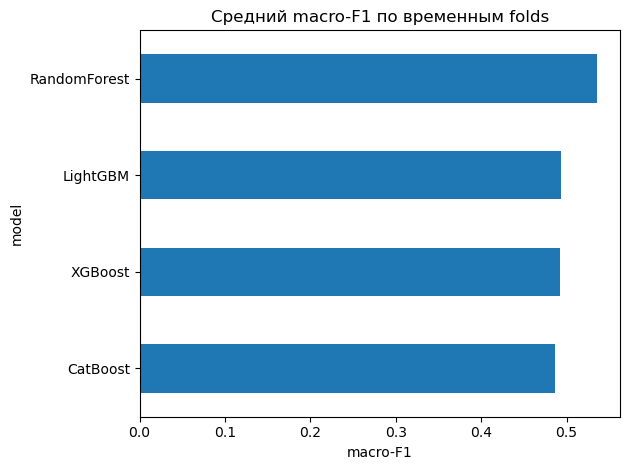

Saved model zoo: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\afml06_outputs\MAGN_AFML06_model_zoo.csv


In [ ]:
best_built=get_labeled_cached(best_params)
if best_built is None: raise RuntimeError("Не удалось восстановить лучший датасет из кэша")
Xbest,ybest,lbest=best_built
best_fold_rows=[]
for fold in FIXED_FOLDS:
    res=eval_fold_config(Xbest,ybest,lbest,fold,best_params,with_clusters=True)
    if res is not None:
        best_fold_rows.append({"fold":fold["name"],**res})
best_fold_df=pd.DataFrame(best_fold_rows)
display(best_fold_df)
best_fold_path=OUT_DIR/f"{TICKER}_AFML06_best_config_fold_metrics.csv"
best_fold_df.to_csv(best_fold_path,index=False,encoding="utf-8-sig")


def evaluate_model_zoo(X,y,labels,folds,scaler_name):
    rows=[]
    for fold in folds:
        tr=X.index[X.index <= fold["train_end_ts"]]
        va=X.index[(X.index >= fold["val_start"]) & (X.index <= fold["val_end"])]
        t1=labels.reindex(tr)["t1"]
        tr=tr[(t1.notna() & (t1<fold["val_start"])).to_numpy()]
        t1v=labels.reindex(va)["t1"]
        va=va[(t1v.notna() & (t1v<=fold["val_end"])).to_numpy()]
        if len(tr)<100 or len(va)<30 or y.loc[tr].nunique()<2: continue
        A,B,cols,imp,scaler=prepare_fold_matrices(X.loc[tr],X.loc[va],scaler_name)
        # Apply the selected PCA + DBSCAN configuration identically to every candidate model.
        k=min(int(best_params["pca_components"]),A.shape[1],max(1,A.shape[0]-1))
        pca=PCA(n_components=k,svd_solver="randomized",random_state=SEED)
        Ptr=pca.fit_transform(A); Pva=pca.transform(B)
        clusterer=DBSCAN(eps=float(best_params["dbscan_eps"]),min_samples=int(best_params["dbscan_min_samples"]),n_jobs=1)
        ctr=clusterer.fit_predict(Ptr)
        core_mask=np.zeros(len(Ptr),dtype=bool); core_mask[clusterer.core_sample_indices_]=True
        cv=dbscan_assign_to_core(Pva,Ptr[core_mask],ctr[core_mask],float(best_params["dbscan_eps"]))
        labs=sorted(set(ctr.tolist()) | set(cv.tolist()))
        tr_oh=np.column_stack([(ctr==lab).astype(float) for lab in labs])
        va_oh=np.column_stack([(cv==lab).astype(float) for lab in labs])
        A_model=np.column_stack([Ptr,tr_oh]); B_model=np.column_stack([Pva,va_oh])
        models={
            "RandomForest":RandomForestClassifier(n_estimators=RF_N_ESTIMATORS,max_depth=RF_MAX_DEPTH,min_samples_leaf=RF_MIN_SAMPLES_LEAF,
                                                  max_features=RF_MAX_FEATURES,class_weight="balanced_subsample",random_state=SEED,n_jobs=-1),
            "XGBoost": XGBClassifier(n_estimators=250, max_depth=RF_MAX_DEPTH, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, 
                                     reg_lambda=1.0, random_state=SEED, verbosity=0, n_jobs=-1, use_label_encoder=False, eval_metric="logloss"),
            "LightGBM": LGBMClassifier(n_estimators=250, max_depth=RF_MAX_DEPTH, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                                       reg_lambda=1.0, random_state=SEED, verbosity=-1, n_jobs=-1),
            "CatBoost": CatBoostClassifier(iterations=250, depth=RF_MAX_DEPTH, learning_rate=0.05, l2_leaf_reg=1.0, random_seed=SEED, 
                                           verbose=False, allow_writing_files=False,thread_count=-1),}
        
        for name,model in models.items():
            try:
                model.fit(A_model,y.loc[tr]); pred=model.predict(B_model)
                rows.append({"fold":fold["name"],"model":name,"n_train":len(tr),"n_valid":len(va),
                    "pca_components_used":k,"pca_explained_variance":float(pca.explained_variance_ratio_.sum()),
                    "n_clusters_train":len(set(ctr.tolist())-{-1}),"noise_train":float(np.mean(ctr==-1)),"noise_valid":float(np.mean(cv==-1)),
                    **score_predictions(y.loc[va],pred)})
            except Exception as e:
                rows.append({"fold":fold["name"],"model":name,"status":str(e)[:250]})
        del A,B,A_model,B_model,Ptr,Pva,models; gc.collect()
    return pd.DataFrame(rows)

model_zoo=evaluate_model_zoo(Xbest,ybest,lbest,FIXED_FOLDS,best_params["scaler"])
model_zoo_path=OUT_DIR/f"{TICKER}_AFML06_model_zoo.csv"
model_zoo.to_csv(model_zoo_path,index=False,encoding="utf-8-sig")
display(model_zoo)
if not model_zoo.empty:
    summary=model_zoo.groupby("model").agg({"f1_macro":["mean","std"],"f1_up":["mean","std"],"balanced_accuracy":["mean","std"]})
    display(summary)
    model_zoo.groupby("model")["f1_macro"].mean().sort_values().plot(kind="barh",title="Средний macro-F1 по временным folds")
    plt.xlabel("macro-F1"); plt.tight_layout(); plt.show()
print("Saved model zoo:",model_zoo_path)

## 8. Чек-лист интерпретации

1. Сначала смотри `*_AFML06_optuna_trials.csv`: какие конфигурации получили валидные folds, какой `macro-F1`, `F1 +1`, baseline-vs-cluster разница и доля шума.
2. Если лучший DBSCAN снова помечает почти всё как шум — не делай вывод, что данные лишены режимов: проверь расстояния в PCA-пространстве, диапазон `eps` и число компонентов. Текущий objective отбрасывает вырожденные конфигурации, но это диагностический фильтр, а не доказательство наличия кластеров.
3. Сравни средний macro-F1 и разброс по folds. Небольшой рост на одном fold при падении на остальных не считать улучшением.
4. Сохрани JSON `*_best_data_cluster_config.json`: это паспорт конфигурации датасета/кластеризации для следующих экспериментов.
5. Не трактуй рост F1 как альфу. После выбора конфигурации — отдельная проверка на нетронутом holdout и только затем canonical backtest engine.

**Ограничение:** файл построен по текущему контракту `jerichon_feature_pipeline.py` и labeling helpers. В этой среде нет доступа к твоему локальному репозиторию AlgoPack, поэтому ноутбук проходит синтаксическую проверку, но реальное исполнение на твоих parquet-данных здесь не подтверждено.